In [259]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix
)

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [260]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nChurn Distribution:")
print(df["Churn"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [261]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Missing values in TotalCharges:", df["TotalCharges"].isnull().sum())

TotalCharges data type: float64
Missing values in TotalCharges: 11


In [262]:
print("Missing TotalCharges after conversion:")
print(df["TotalCharges"].isnull().sum())

Missing TotalCharges after conversion:
11


In [263]:
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

print("Missing TotalCharges after imputation:",
      df["TotalCharges"].isnull().sum())

Missing TotalCharges after imputation: 0


In [264]:
# Remove customer ID
df = df.drop("customerID", axis=1)

# Separate features and target
X = df.drop("Churn", axis=1)
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [265]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Identify column types
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Fit on training data and transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Processed training shape:", X_train_processed.shape)

Training samples: 5634
Testing samples: 1409
Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Processed training shape: (5634, 45)


In [266]:
!pip install imbalanced-learn -q

In [267]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


In [268]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_smote, y_train_smote)

# Predict probabilities
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]

# Calculate ROC-AUC
rf_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest ROC-AUC:", round(rf_auc, 4))

Random Forest ROC-AUC: 0.8162


In [269]:
!pip install xgboost -q

In [270]:
from xgboost import XGBClassifier

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

# Train the model
xgb_model.fit(X_train_smote, y_train_smote)

# Predict probabilities
xgb_prob = xgb_model.predict_proba(X_test_processed)[:, 1]

# Calculate ROC-AUC
xgb_auc = roc_auc_score(y_test, xgb_prob)

print("XGBoost ROC-AUC:", round(xgb_auc, 4))

XGBoost ROC-AUC: 0.841


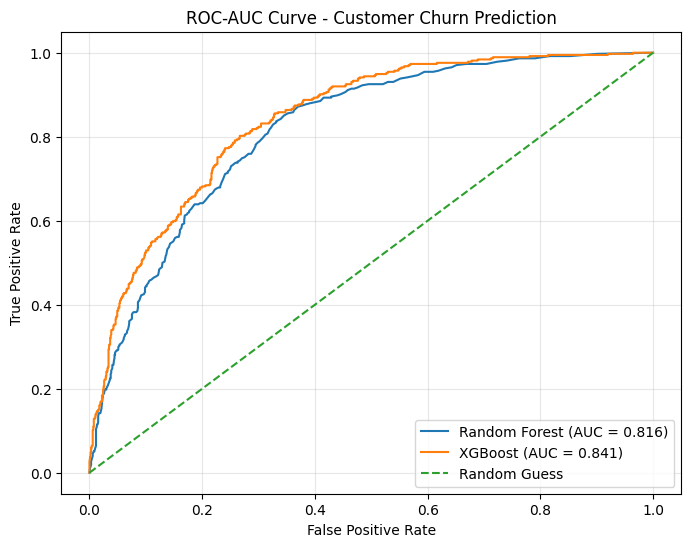

In [271]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC curves
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_prob)

rf_roc_auc = auc(rf_fpr, rf_tpr)
xgb_roc_auc = auc(xgb_fpr, xgb_tpr)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr, rf_tpr,
    label=f"Random Forest (AUC = {rf_roc_auc:.3f})"
)

plt.plot(
    xgb_fpr, xgb_tpr,
    label=f"XGBoost (AUC = {xgb_roc_auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve - Customer Churn Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [272]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get XGBoost feature importance
importance = xgb_model.feature_importances_

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort and select top 10
top_10_features = feature_importance.sort_values(
    by="Importance",
    ascending=False
).head(10)

print("Top 10 Most Important Features:")
print(top_10_features)

Top 10 Most Important Features:
                                Feature  Importance
36         cat__Contract_Month-to-month    0.248680
18               cat__OnlineSecurity_No    0.126161
16     cat__InternetService_Fiber optic    0.058661
27                  cat__TechSupport_No    0.049146
43  cat__PaymentMethod_Electronic check    0.041747
38               cat__Contract_Two year    0.030097
37               cat__Contract_One year    0.027738
39             cat__PaperlessBilling_No    0.024909
21                 cat__OnlineBackup_No    0.024282
8                    cat__Dependents_No    0.021879


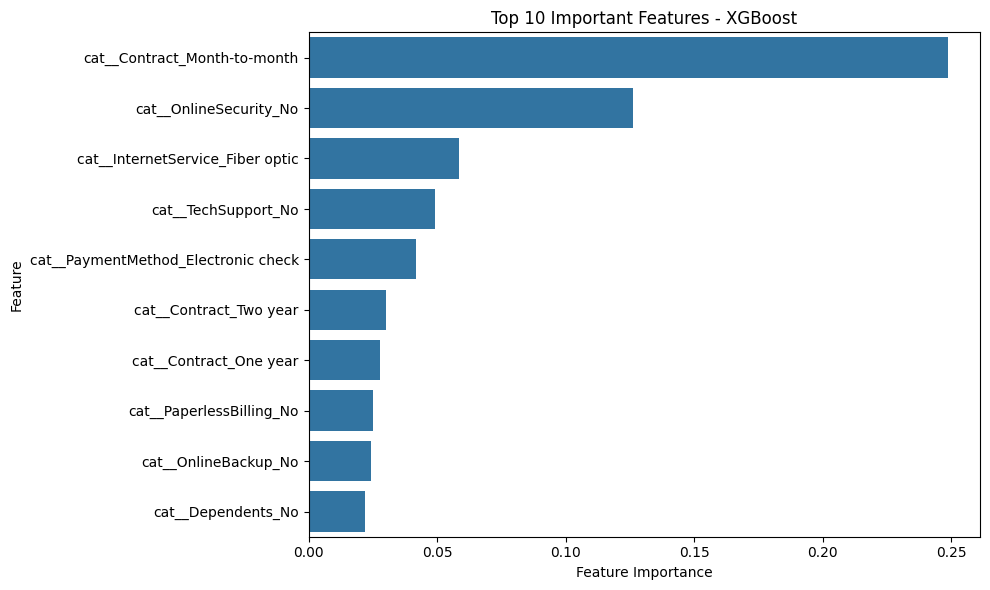

In [273]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [274]:
# Create final comparison table
final_results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "ROC-AUC": [rf_auc, xgb_auc]
})

final_results["ROC-AUC"] = final_results["ROC-AUC"].round(4)

print("FINAL MODEL COMPARISON")
print("=" * 40)
print(final_results.to_string(index=False))

best_model = final_results.loc[
    final_results["ROC-AUC"].idxmax(), "Model"
]

best_auc = final_results["ROC-AUC"].max()

print("\nBest Model:", best_model)
print("Best ROC-AUC:", best_auc)

FINAL MODEL COMPARISON
        Model  ROC-AUC
Random Forest   0.8162
      XGBoost   0.8410

Best Model: XGBoost
Best ROC-AUC: 0.841


In [ ]:
## Conclusion

The Telco Customer Churn dataset was used to build a customer attrition prediction system.

The data was preprocessed by converting TotalCharges to numeric values, handling missing values, removing the customer ID, encoding categorical features using OneHotEncoder, and standardizing numerical features.

SMOTE was used to balance the training classes because the dataset contained more non-churn customers than churn customers.

Two ensemble machine learning models were trained:
- Random Forest
- XGBoost

The models were evaluated using ROC-AUC. Random Forest achieved an ROC-AUC of 0.8162, while XGBoost achieved 0.8410.

XGBoost performed better and achieved an ROC-AUC above 80%, satisfying the task requirement. The ROC-AUC curves and top 10 feature importance analysis were also performed.

Overall, this project demonstrates a complete customer churn prediction workflow using preprocessing, class balancing, ensemble learning, ROC-AUC evaluation, and feature importance analysis.